In [1]:
pip install pandas pyodbc sqlalchemy

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
from sqlalchemy import create_engine
import urllib

# 1. Define your SQL Server connection details
server = r'RISHIRAJ\SQLEXPRESS'
database = 'Financial_Capstone'
driver = 'SQL Server'  # Changed to the universal Windows default

# 2. Create the connection string
connection_string = f"Driver={{{driver}}};Server={server};Database={database};Trusted_Connection=yes;"
params = urllib.parse.quote_plus(connection_string)
engine = create_engine(f"mssql+pyodbc:///?odbc_connect={params}")

# 3. Load the SQL tables into pandas DataFrames
print("Connecting to SQL Server and loading data...")

df_customers = pd.read_sql("SELECT * FROM Customers", engine)
df_vendors = pd.read_sql("SELECT * FROM Vendors", engine)
df_headcount = pd.read_sql("SELECT * FROM Headcount", engine)
df_budget = pd.read_sql("SELECT * FROM Budget", engine)
df_transactions = pd.read_sql("SELECT * FROM Financial_Transactions", engine)

# 4. Validate the row counts post-load
print("\n--- Row Counts Validated ---")
print(f"Customers: {len(df_customers)} rows")
print(f"Vendors: {len(df_vendors)} rows")
print(f"Headcount: {len(df_headcount)} rows")
print(f"Budget: {len(df_budget)} rows")
print(f"Transactions: {len(df_transactions)} rows")

Connecting to SQL Server and loading data...


C:\Users\rishi\anaconda3\Lib\site-packages\pandas\io\sql.py:1648: SAWarning: Unrecognized server version info '17.0.1145.4'.  Some SQL Server features may not function properly.
  con = self.exit_stack.enter_context(con.connect())



--- Row Counts Validated ---
Customers: 400 rows
Vendors: 120 rows
Headcount: 200 rows
Budget: 72 rows
Transactions: 10400 rows


--- Missing Values in Transactions ---
transaction_id         0
transaction_date       0
amount                 0
account_type           0
category               0
business_unit          0
region                 0
customer_id         4886
vendor_id           6275
description            0
dtype: int64

--- Summary Statistics (Transaction Amount) ---
count     10400.000000
mean      68456.676368
std      103041.354633
min     -113310.710000
25%      -33691.872500
50%       78624.650000
75%      157303.552500
max      351386.850000
Name: amount, dtype: float64


C:\Users\rishi\AppData\Local\Temp\ipykernel_23792\4073667795.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_transactions, x='Transaction_Type', palette='viridis')


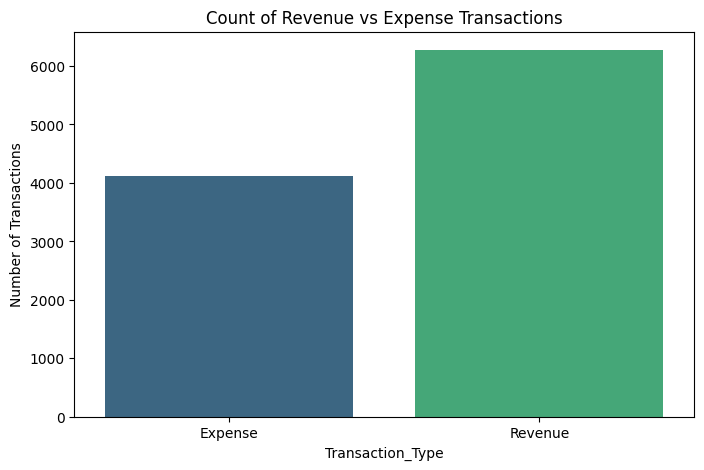

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Check for missing values in the Transactions table
print("--- Missing Values in Transactions ---")
print(df_transactions.isnull().sum())

# 2. Descriptive statistics for transaction amounts
print("\n--- Summary Statistics (Transaction Amount) ---")
# Convert amount to numeric just in case it loaded as a string
df_transactions['amount'] = pd.to_numeric(df_transactions['amount'], errors='coerce')
print(df_transactions['amount'].describe())

# 3. Quick EDA Visualization: Revenue vs Expenses count
# We can determine Revenue (positive) and Expense (negative) based on the amount
df_transactions['Transaction_Type'] = df_transactions['amount'].apply(lambda x: 'Revenue' if x > 0 else 'Expense')

plt.figure(figsize=(8, 5))
sns.countplot(data=df_transactions, x='Transaction_Type', palette='viridis')
plt.title('Count of Revenue vs Expense Transactions')
plt.ylabel('Number of Transactions')
plt.show()

--- Actuals vs Budget Variance (First 10 Rows) ---


,year,month,business_unit,Expense,Revenue,budgeted_revenue,budgeted_expense,Revenue_Variance,Expense_Variance,Actual_Profit,Budgeted_Profit
0,2022.0,1.0,Enterprise,1198075.54,4435242.83,1689240,1152615,2746002.83,45460.54,3237167.29,536625
1,2022.0,1.0,Online,1018842.30,4253370.51,2069088,1776169,2184282.51,-757326.70,3234528.21,292919
2,2022.0,1.0,Retail,955008.02,3214201.65,1530660,1259760,1683541.65,-304751.98,2259193.63,270900
3,2022.0,2.0,Enterprise,549377.21,3417822.77,1923012,1454263,1494810.77,-904885.79,2868445.56,468749
4,2022.0,2.0,Online,968799.11,3233125.29,1516272,1117069,1716853.29,-148269.89,2264326.18,399203
5,2022.0,2.0,Retail,1196293.61,3673788.03,1836984,1201730,1836804.03,-5436.39,2477494.42,635254
6,2022.0,3.0,Enterprise,979989.65,5164932.04,1576692,959653,3588240.04,20336.65,4184942.39,617039
7,2022.0,3.0,Online,1118067.61,4149333.10,2119464,1677676,2029869.10,-559608.39,3031265.49,441788
8,2022.0,3.0,Retail,977314.67,4649039.86,1510920,1106833,3138119.86,-129518.33,3671725.19,404087
9,2022.0,4.0,Enterprise,988449.64,3255018.28,2042184,1592655,1212834.28,-604205.36,2266568.64,449529


C:\Users\rishi\AppData\Local\Temp\ipykernel_23792\3891385402.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=budget_variance, x='business_unit', y='Actual_Profit', estimator=sum, errorbar=None, palette='mako')


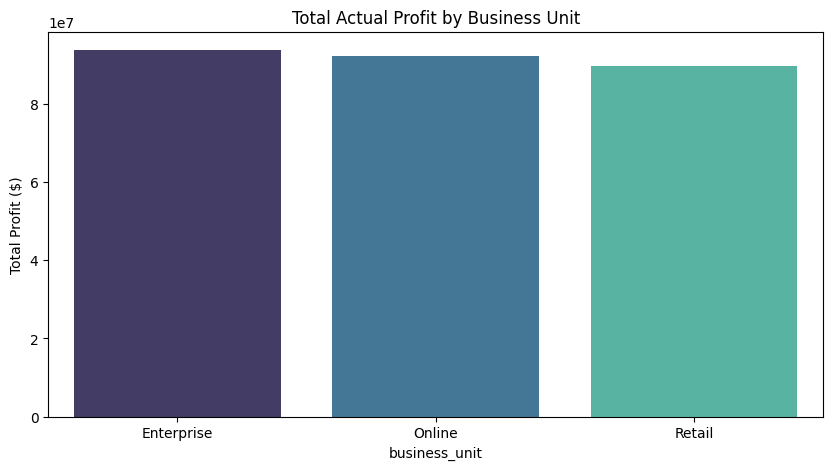

In [5]:
# 1. Convert date strings back to actual datetime objects for analysis
df_transactions['transaction_date'] = pd.to_datetime(df_transactions['transaction_date'], errors='coerce')
df_transactions['year'] = df_transactions['transaction_date'].dt.year
df_transactions['month'] = df_transactions['transaction_date'].dt.month

# 2. Group transactions to get actual total revenue and expense per business unit per month
actuals = df_transactions.groupby(['year', 'month', 'business_unit', 'Transaction_Type'])['amount'].sum().unstack().fillna(0).reset_index()
# Expenses are negative in the data, so make them positive for easier comparison against the budget
actuals['Expense'] = actuals['Expense'].abs()

# 3. Merge actuals with the Budget dataframe
budget_variance = pd.merge(actuals, df_budget, on=['year', 'month', 'business_unit'], how='inner')

# 4. Calculate Variances (Actual - Budget)
budget_variance['Revenue_Variance'] = budget_variance['Revenue'] - budget_variance['budgeted_revenue']
budget_variance['Expense_Variance'] = budget_variance['Expense'] - budget_variance['budgeted_expense']
# Profit = Revenue - Expense
budget_variance['Actual_Profit'] = budget_variance['Revenue'] - budget_variance['Expense']
budget_variance['Budgeted_Profit'] = budget_variance['budgeted_revenue'] - budget_variance['budgeted_expense']

# 5. Display the final merged DataFrame ready for hypothesis testing or dashboarding
print("--- Actuals vs Budget Variance (First 10 Rows) ---")
display(budget_variance.head(10))

# 6. Quick EDA: Total Profit by Business Unit
plt.figure(figsize=(10, 5))
sns.barplot(data=budget_variance, x='business_unit', y='Actual_Profit', estimator=sum, errorbar=None, palette='mako')
plt.title('Total Actual Profit by Business Unit')
plt.ylabel('Total Profit ($)')
plt.show()

In [6]:
import scipy.stats as stats

print("--- Step 7: Statistical Analysis & Hypothesis Testing ---\n")

# Hypothesis 1: ANOVA Test on Expenses across Business Units
# Null Hypothesis (H0): Mean monthly expenses are equal across Enterprise, Online, and Retail.
enterprise_exp = budget_variance[budget_variance['business_unit'] == 'Enterprise']['Expense']
online_exp = budget_variance[budget_variance['business_unit'] == 'Online']['Expense']
retail_exp = budget_variance[budget_variance['business_unit'] == 'Retail']['Expense']

f_stat, p_val_anova = stats.f_oneway(enterprise_exp, online_exp, retail_exp)

print("1. ANOVA Test: Monthly Expenses across Business Units")
print(f"F-Statistic: {f_stat:.2f}, p-value: {p_val_anova:.4f}")
if p_val_anova < 0.05:
    print("Conclusion: Reject the Null Hypothesis. There IS a statistically significant difference in mean expenses between the business units.\n")
else:
    print("Conclusion: Fail to reject the Null Hypothesis. There is NO statistically significant difference in mean expenses between the business units.\n")


# Hypothesis 2: Paired T-Test on Actual Profit vs Budgeted Profit
# Null Hypothesis (H0): The mean actual profit is equal to the mean budgeted profit.
t_stat, p_val_ttest = stats.ttest_rel(budget_variance['Actual_Profit'], budget_variance['Budgeted_Profit'])

print("2. Paired T-Test: Actual Profit vs Budgeted Profit")
print(f"T-Statistic: {t_stat:.2f}, p-value: {p_val_ttest:.4f}")
if p_val_ttest < 0.05:
    print("Conclusion: Reject the Null Hypothesis. The actual profit generated is significantly different from the budgeted profit.")
else:
    print("Conclusion: Fail to reject the Null Hypothesis. There is no significant difference between actual and budgeted profit.")

--- Step 7: Statistical Analysis & Hypothesis Testing ---

1. ANOVA Test: Monthly Expenses across Business Units
F-Statistic: 0.32, p-value: 0.7238
Conclusion: Fail to reject the Null Hypothesis. There is NO statistically significant difference in mean expenses between the business units.

2. Paired T-Test: Actual Profit vs Budgeted Profit
T-Statistic: 26.30, p-value: 0.0000
Conclusion: Reject the Null Hypothesis. The actual profit generated is significantly different from the budgeted profit.
